In [18]:
import os
import zipfile

zip_path = "/content/machinelearninginaction/Ch02/digits.zip"
extract_path = "/content/machinelearninginaction/Ch02"

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_path)

print("Dataset extracted successfully!")
print(os.listdir(extract_path))

Dataset extracted successfully!
['kNN.py', 'testDigits', 'datingTestSet.txt', 'trainingDigits', 'README.txt', 'datingTestSet2.txt', 'digits.zip', 'EXTRAS']


In [19]:
import os

base_path = "/content/machinelearninginaction/Ch02"

for root, dirs, files in os.walk(base_path):
    if "trainingDigits" in dirs:
        train_dir = os.path.join(root, "trainingDigits")
    if "testDigits" in dirs:
        test_dir = os.path.join(root, "testDigits")

print("Training folder:", train_dir)
print("Testing folder:", test_dir)

Training folder: /content/machinelearninginaction/Ch02/trainingDigits
Testing folder: /content/machinelearninginaction/Ch02/testDigits


In [20]:
import numpy as np

def img2vector(filename):
    with open(filename, "r") as f:
        lines = f.readlines()
    return np.array([
        int(lines[i][j])
        for i in range(32)
        for j in range(32)
    ])

X_train, y_train = [], []
X_test, y_test = [], []

for filename in sorted(os.listdir(train_dir)):
    if filename.endswith(".txt"):
        X_train.append(img2vector(os.path.join(train_dir, filename)))
        y_train.append(int(filename.split("_")[0]))

for filename in sorted(os.listdir(test_dir)):
    if filename.endswith(".txt"):
        X_test.append(img2vector(os.path.join(test_dir, filename)))
        y_test.append(int(filename.split("_")[0]))

X_train = np.array(X_train)
X_test = np.array(X_test)
y_train = np.array(y_train)
y_test = np.array(y_test)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1934, 1024)
Testing data: (946, 1024)


In [21]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train, y_train)

y_pred = knn.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 98.84 %
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        87
           1       0.97      0.99      0.98        97
           2       1.00      1.00      1.00        92
           3       0.98      0.99      0.98        85
           4       1.00      1.00      1.00       114
           5       0.99      0.98      0.99       108
           6       0.98      1.00      0.99        87
           7       0.98      1.00      0.99        96
           8       1.00      0.96      0.98        91
           9       0.99      0.97      0.98        89

    accuracy                           0.99       946
   macro avg       0.99      0.99      0.99       946
weighted avg       0.99      0.99      0.99       946



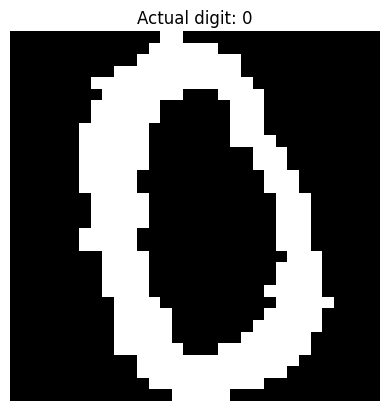

Actual digit: 0
Predicted digit: 0


In [22]:
import matplotlib.pyplot as plt

i = 0

plt.imshow(X_test[i].reshape(32, 32), cmap="gray")
plt.title("Actual digit: " + str(y_test[i]))
plt.axis("off")
plt.show()

print("Actual digit:", y_test[i])
print("Predicted digit:", knn.predict(X_test[i].reshape(1, -1))[0])